# 06 Visualization

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (13, 7)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.dpi"] = 160


DATA_DIR = Path("/content/drive/MyDrive/NLP_Final_Project")
FIG_DIR = DATA_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True, parents=True)

Mounted at /content/drive


In [14]:
def prep_month_ticks(df, month_col="month", step=4):
    months = df[month_col].astype(str).tolist()
    tick_idx = list(range(0, len(months), step))
    tick_labels = [months[i] for i in tick_idx]
    return tick_idx, tick_labels


def finalize_plot(title, ylabel, save_path=None):
    plt.title(title)
    plt.xlabel("Month")
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.grid(alpha=0.2)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

### Load sentiment artifacts

We load the sentence-level, document-level, topic-time, and entity-time sentiment outputs generated in Stage E.

In [2]:
sent_sentence = pd.read_parquet(DATA_DIR / "sent_sentence.parquet")
sent_doc = pd.read_parquet(DATA_DIR / "sent_doc.parquet")
sent_topic_time = pd.read_csv(DATA_DIR / "sent_topic_time.csv")
sent_entity_time = pd.read_csv(DATA_DIR / "sent_entity_time.csv")

print("sent_sentence:", sent_sentence.shape)
print("sent_doc:", sent_doc.shape)
print("sent_topic_time:", sent_topic_time.shape)
print("sent_entity_time:", sent_entity_time.shape)

sent_sentence: (596714, 11)
sent_doc: (99770, 9)
sent_topic_time: (852, 6)
sent_entity_time: (166158, 6)


In [3]:
print(sent_sentence.columns.tolist())

['url', 'date', 'topic_label', 'macro_topic', 'org_list', 'tech_list', 'sentence', 'prob_negative', 'prob_uncertain', 'prob_positive', 'pred_label']


### Industry sentiment over time

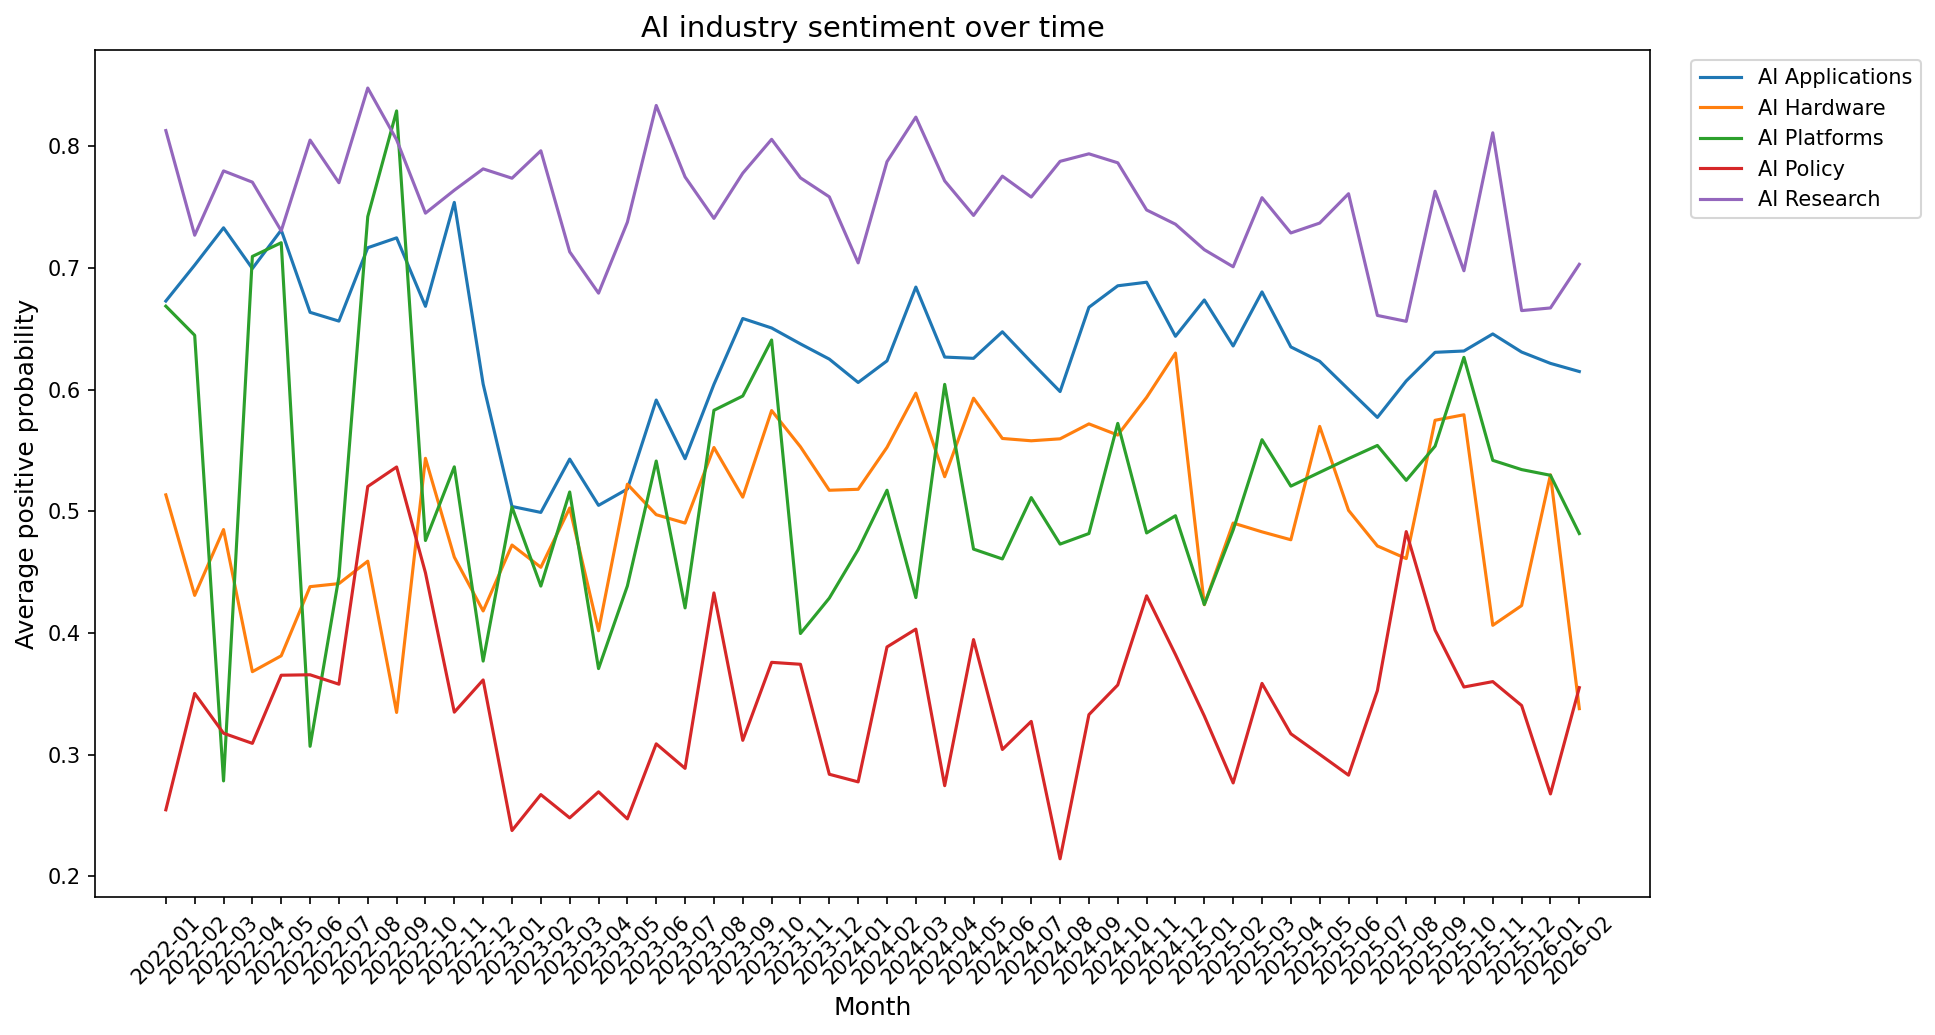

In [15]:
sent_doc["month"] = pd.to_datetime(sent_doc["date"]).dt.to_period("M").astype(str)

industry_df = (
    sent_doc
    .groupby(["month","macro_topic"])["prob_positive"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13,7))

for ind in industry_df["macro_topic"].unique():
    tmp = industry_df[industry_df["macro_topic"]==ind]
    plt.plot(tmp["month"].astype(str), tmp["prob_positive"], label=ind)

plt.xticks(rotation=45)
plt.title("AI industry sentiment over time")
plt.xlabel("Month")
plt.ylabel("Average positive probability")

plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "industry_sentiment_over_time.png", bbox_inches="tight")

plt.show()

### Topic sentiment over time (Top 8 topics)

We first visualize sentiment evolution across the top 8 most frequently discussed topics in the corpus.

In [18]:
top_topics = (
    sent_topic_time.groupby("topic_label")["n_sentences"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .index
)

topic_plot_df = sent_topic_time[
    sent_topic_time["topic_label"].isin(top_topics)
].copy()

topic_plot_df = topic_plot_df.sort_values(["topic_label", "month"])

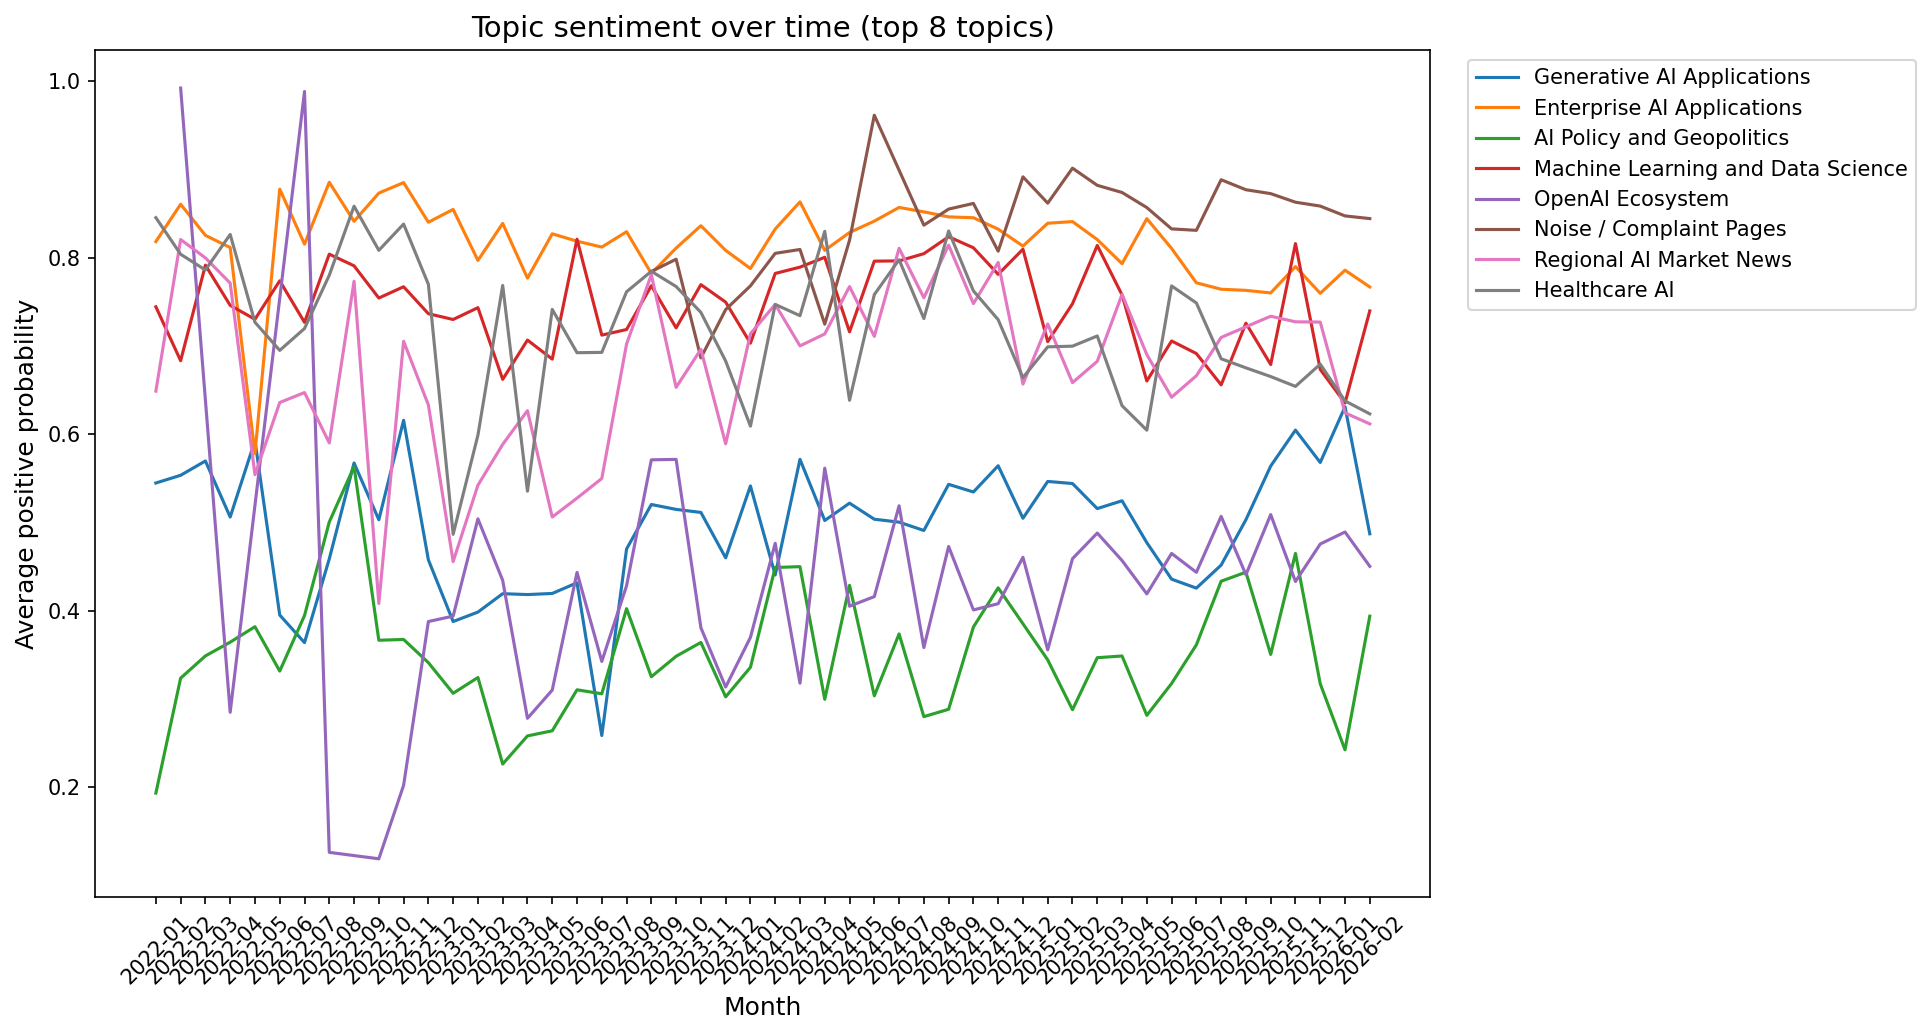

In [20]:
plt.figure(figsize=(13, 7))

for topic in top_topics:
    tmp = topic_plot_df[topic_plot_df["topic_label"] == topic]
    plt.plot(tmp["month"], tmp["avg_positive"], label=topic)

plt.xticks(rotation=45)
plt.title("Topic sentiment over time (top 8 topics)")
plt.xlabel("Month")
plt.ylabel("Average positive probability")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "topic_sentiment_over_time_top8.png", bbox_inches="tight")
plt.show()

### Top companies sentiment over time

We then examine how sentiment evolves over time for the most frequently mentioned companies in the corpus.

In [16]:
top_entities = (
    sent_entity_time.groupby("entity")["n_sentences"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .index
)

entity_plot_df = sent_entity_time[
    sent_entity_time["entity"].isin(top_entities)
].copy()

entity_plot_df = entity_plot_df.sort_values(["entity", "month"])

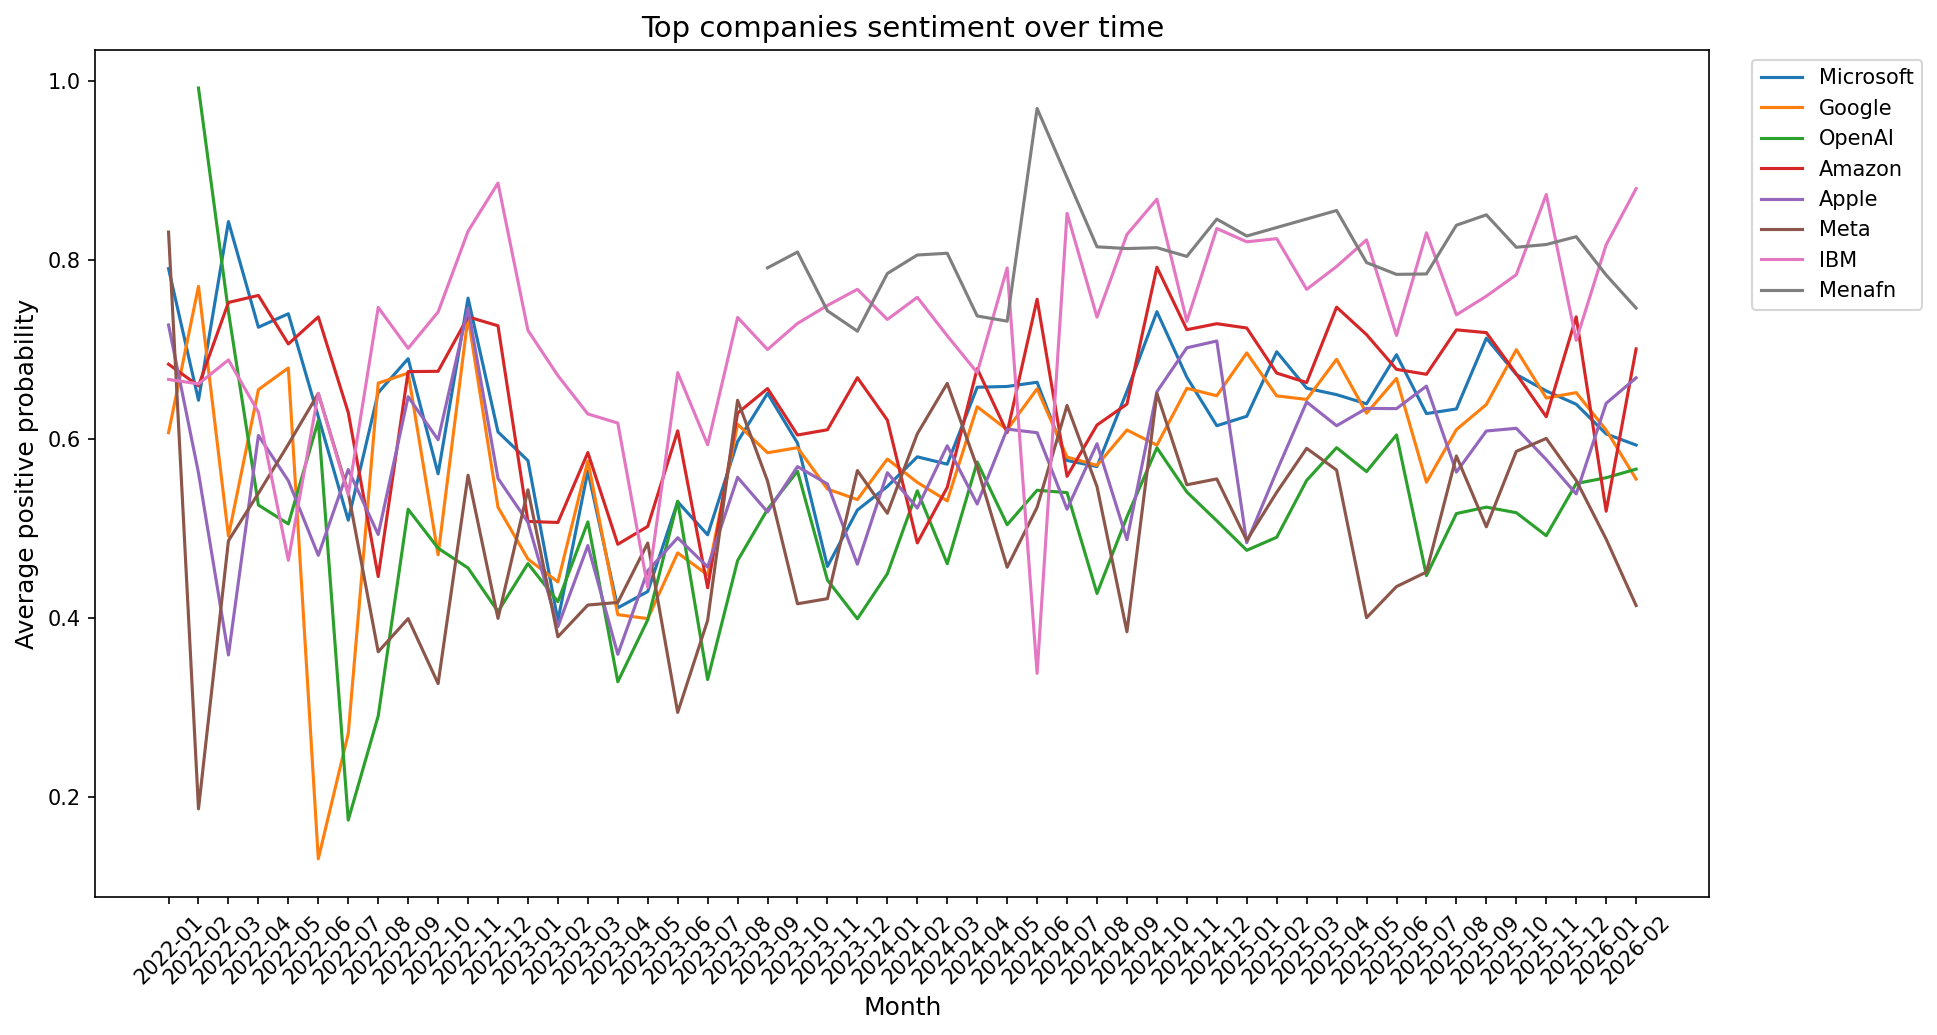

In [17]:
plt.figure(figsize=(13, 7))

for ent in top_entities:
    tmp = entity_plot_df[entity_plot_df["entity"] == ent]
    plt.plot(tmp["month"], tmp["avg_positive"], label=ent)

plt.xticks(rotation=45)
plt.title("Top companies sentiment over time")
plt.xlabel("Month")
plt.ylabel("Average positive probability")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "top_companies_sentiment_over_time.png", bbox_inches="tight")
plt.show()

### Technology Sentiment


In [10]:
tech_df = sent_sentence.copy()

tech_df = tech_df.explode("tech_list")

tech_df["month"] = pd.to_datetime(tech_df["date"]).dt.to_period("M")

In [11]:
tech_sent = (
    tech_df
    .groupby(["month","tech_list"])["prob_positive"]
    .mean()
    .reset_index()
)

In [12]:
top_tech = (
    tech_df["tech_list"]
    .value_counts()
    .head(8)
    .index
)

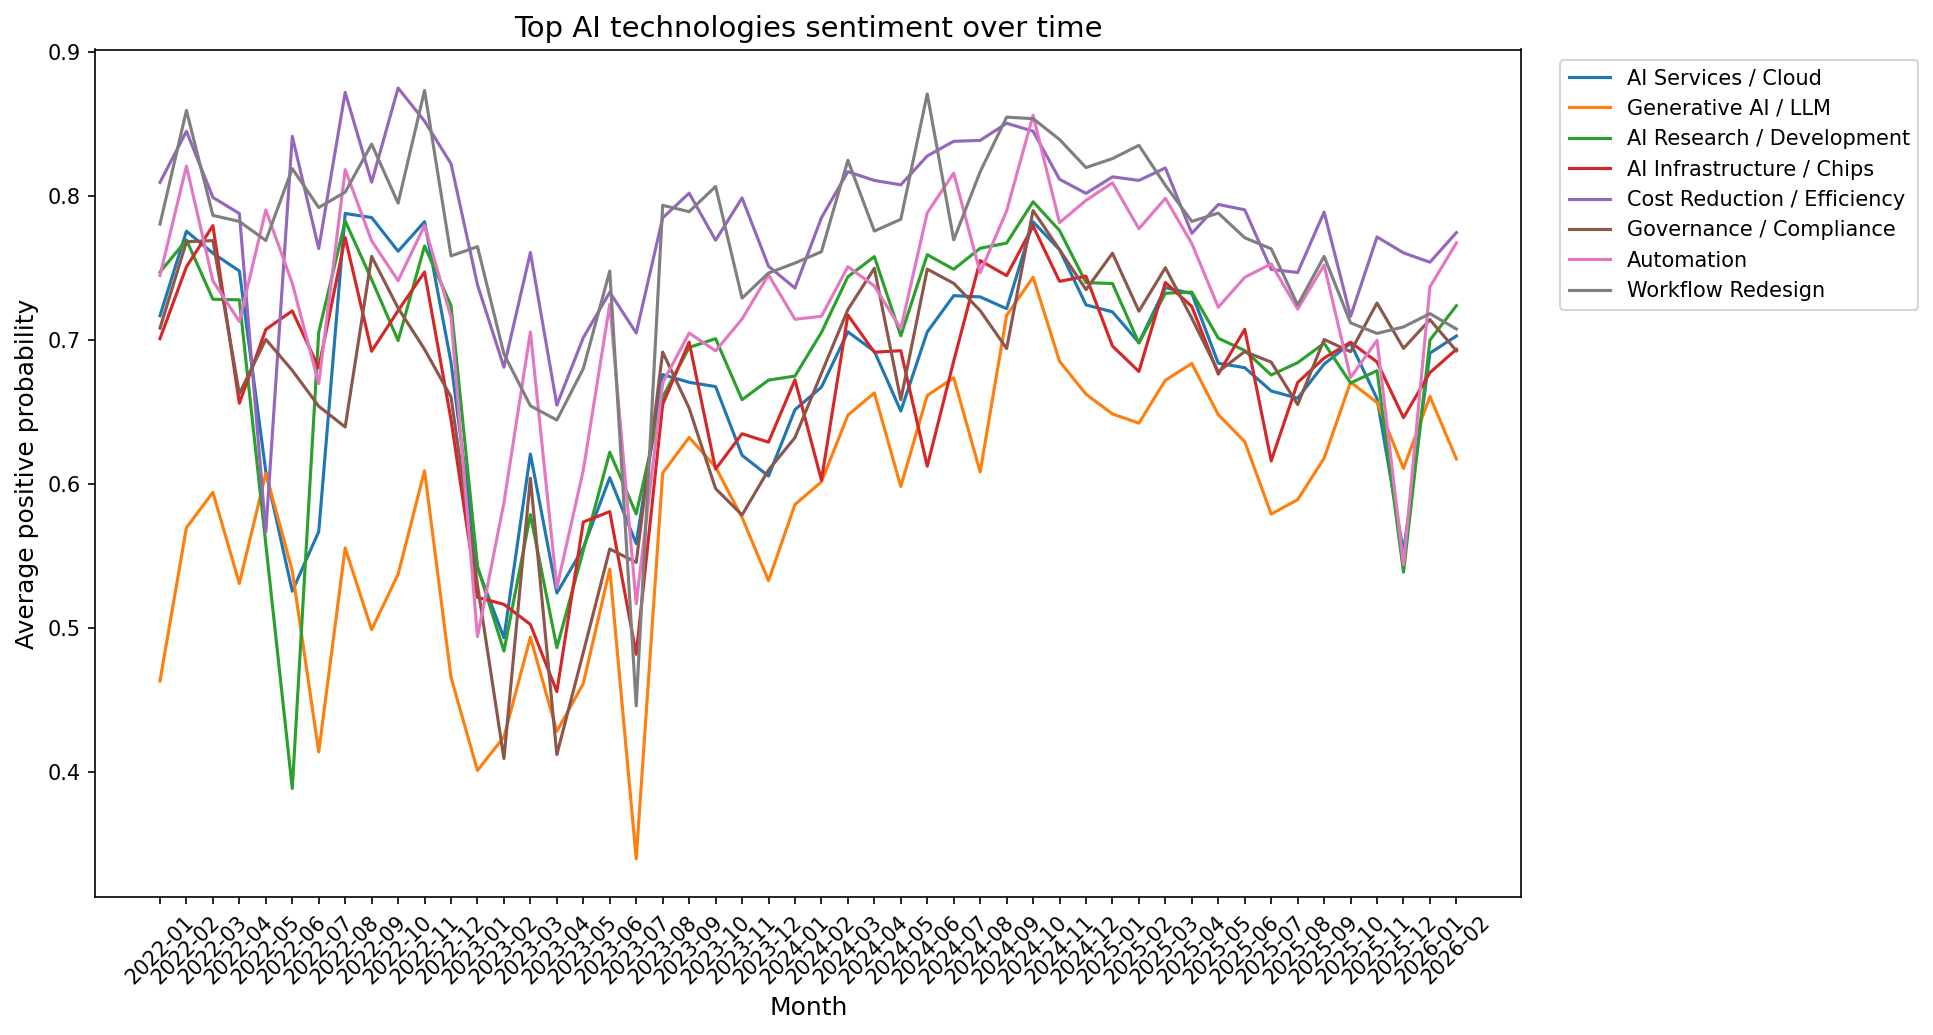

In [13]:
plt.figure(figsize=(13,7))

for tech in top_tech:
    tmp = tech_sent[tech_sent["tech_list"]==tech]
    plt.plot(tmp["month"].astype(str), tmp["prob_positive"], label=tech)

plt.xticks(rotation=45)
plt.title("Top AI technologies sentiment over time")
plt.xlabel("Month")
plt.ylabel("Average positive probability")

plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "tech_sentiment_over_time.png", bbox_inches="tight")

plt.show()